# Kiosk sessions

This is a payment-operations log for self-serve kiosks. A tenant runs stores. A store runs kiosks. A guest walks up, starts a visit, and either pays or walks away.

The business question: which visits finish a purchase, and where should someone step in. Discovery tables come first so the charts are not guessing. Outputs were saved from the repo root.


In [2]:
%matplotlib inline
import html
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "sql" / "init_ddl.sql").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

con = duckdb.connect()
con.execute((ROOT / "data" / "sql" / "init_ddl.sql").read_text())

TITLE = 14
POINT = 8
PANEL = "#EAEAF2"
plt.rcParams.update(
    {
        "figure.facecolor": PANEL,
        "savefig.facecolor": PANEL,
        "axes.facecolor": PANEL,
        "axes.edgecolor": "white",
        "axes.labelcolor": "#1B2838",
        "axes.titlecolor": "#1B2838",
        "text.color": "#1B2838",
        "xtick.color": "#3C3C4A",
        "ytick.color": "#3C3C4A",
        "axes.prop_cycle": plt.cycler(color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"]),
    }
)

LEGEND = dict(
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#D5D5E2",
    framealpha=0.95,
    borderpad=0.4,
    labelspacing=0.35,
    handlelength=1.6,
    handletextpad=0.5,
)


def place_legend(fig, handles, labels):
    fig.tight_layout(rect=(0, 0, 0.76, 1))
    fig.legend(
        handles,
        labels,
        loc="center left",
        bbox_to_anchor=(0.78, 0.5),
        **LEGEND,
    )


def tenant_name(value):
    return str(value).replace("tenant_", "Tenant ")


def short_num(value):
    value = float(value)
    if abs(value) >= 1000:
        return f"{value / 1000:.1f}k"
    return f"{value:.0f}"


def polish(ax, title, xlabel=None, ylabel=None, grid="both"):
    ax.figure.set_facecolor(PANEL)
    ax.set_facecolor(PANEL)
    ax.set_title(title, fontsize=TITLE, pad=12, color="#1B2838")
    ax.tick_params(labelsize=8, colors="#3C3C4A")
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9, color="#1B2838")
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9, color="#1B2838")
    for spine in ax.spines.values():
        spine.set_color("white")
        spine.set_linewidth(1)
    ax.set_axisbelow(True)
    ax.grid(False)
    if grid in ("y", "both"):
        ax.yaxis.grid(True, color="white", linewidth=1)
    if grid in ("x", "both"):
        ax.xaxis.grid(True, color="white", linewidth=1)


def point(ax, x, y, text, color="#1B2838", xytext=(0, 2), va="bottom", ha="center", bbox=None):
    ax.annotate(
        text,
        (x, y),
        textcoords="offset points",
        xytext=xytext,
        ha=ha,
        va=va,
        fontsize=POINT,
        color=color,
        bbox=bbox,
    )


pd.set_option("display.colheader_justify", "left")


class LeftTable(pd.DataFrame):
    def _repr_html_(self):
        head = "".join(
            f'<th style="text-align:left">{html.escape(str(col))}</th>' for col in self.columns
        )
        body = []
        for idx, row in self.iterrows():
            cells = "".join(
                f'<td style="text-align:left">{html.escape(str(value))}</td>' for value in row
            )
            body.append(
                f'<tr><th style="text-align:left">{html.escape(str(idx))}</th>{cells}</tr>'
            )
        return (
            '<table class="dataframe">'
            f'<thead><tr><th style="text-align:left"></th>{head}</tr></thead>'
            f"<tbody>{''.join(body)}</tbody></table>"
        )


def show_tenants(frame):
    out = frame.copy()
    if "tenant" in out.columns:
        out["tenant"] = out["tenant"].map(tenant_name)
    return out


def present(frame):
    out = show_tenants(frame)
    shown = pd.DataFrame(index=out.index)
    for col in out.columns:
        series = out[col]
        name = str(col).lower()
        money = "revenue" in name and "count" not in name and not name.startswith("unique_")
        if money:
            numeric = pd.to_numeric(series, errors="coerce")
            if int(numeric.notna().sum()) == int(series.notna().sum()):
                shown[col] = [
                    "" if pd.isna(value) else f"{float(value):.1f}" for value in numeric
                ]
                continue
        if pd.api.types.is_datetime64_any_dtype(series):
            shown[col] = series.dt.strftime("%Y-%m-%dT%H:%M:%S")
        else:
            shown[col] = ["" if pd.isna(value) else str(value) for value in series]
    return LeftTable(shown)


def sql_file(path):
    raw = (ROOT / path).read_text()
    raw = re.sub(r"/\*.*?\*/", "", raw, flags=re.S)
    frames = []
    for chunk in raw.split(";"):
        kept = [line for line in chunk.splitlines() if not line.strip().startswith("--")]
        statement = "\n".join(kept).strip()
        if statement:
            frames.append(present(con.sql(statement).df()))
    return frames


def load_identity():
    global identity, file_counts
    if "identity" not in globals():
        identity = con.sql("""
        SELECT
            session_id,
            MIN(tenant) AS tenant,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            COUNT(DISTINCT tenant) AS tenants,
            COUNT(DISTINCT store_id_unified) AS stores,
            COUNT(DISTINCT kiosk_id_up) AS kiosks,
            COUNT(DISTINCT event_date) AS dates,
            MIN(event_date) AS first_date,
            MAX(event_date) AS last_date
        FROM events
        GROUP BY session_id
        """).df()
    if "file_counts" not in globals():
        file_counts = con.sql("""
        SELECT
            COUNT(*) AS rows,
            COUNT(*) - COUNT(DISTINCT session_id || '|' || CAST(event_index AS VARCHAR)) AS duplicate_pairs
        FROM events
        """).df()
    return identity, file_counts


def load_daily():
    global daily
    if "daily" not in globals():
        daily = con.sql("""
        SELECT
            event_date,
            tenant,
            COUNT(DISTINCT session_id) AS unique_sessions,
            SUM(item_revenue) AS total_item_revenue
        FROM events
        GROUP BY event_date, tenant
        ORDER BY event_date, tenant
        """).df()
    return daily


def load_session_flags():
    global session_flags
    if "session_flags" not in globals():
        session_flags = con.sql("""
        SELECT
            tenant,
            session_id,
            MIN(store_id_unified) AS store,
            MIN(kiosk_id_up) AS kiosk,
            MAX(event_name = 'view_item_list') AS viewed,
            MAX(event_name = 'select_item') AS selected,
            MAX(event_name = 'add_to_cart') AS carted,
            MAX(event_name = 'purchase') AS purchased,
            COUNT(*) FILTER (WHERE event_name = 'purchase') AS purchase_rows,
            COALESCE(SUM(item_revenue) FILTER (WHERE event_name = 'purchase'), 0) AS purchase_revenue
        FROM events
        GROUP BY tenant, session_id
        """).df()
    return session_flags


## What is in the file

`data/sql/discovery_query.sql`. First table is the whole file. Second is the same counts by tenant.

Tenant 1 is the volume business: 32,291 visits against 4,402. Labor, hardware, and any test belong there. Tenant 2's revenue sum looks larger only because its prices use a different unit. Do not rank the brands, or their stores, on that sum. Later charts stay off it.


In [4]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_query.sql"):
    display(frame)


,row_count,unique_tenants_count,unique_sessions_count,unique_event_names_count,unique_event_indexes_count,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum
0,1814373,2,36693,4,353,31,64,596,46176,1142573.7


,tenant,rows,sessions,unique_stores_count,unique_kiosks_count,unique_items_count,non_null_rows_revenue_count,non_null_revenue_sum,min_date,max_date
0,Tenant 1,1648005,32291,29,58,317,40936,440528.7,2026-04-17T00:00:00,2026-05-01T00:00:00
1,Tenant 2,166368,4402,2,6,279,5240,702045.0,2026-04-17T00:00:00,2026-05-01T00:00:00


## Whether a session stays in one place

`data/sql/discovery_grain.sql`. One row is one event.

A visit does not hop stores or kiosks. A weak purchase rate belongs to that store, so you can coach the site without wondering if the guest split the trip. The 46 repeated `session_id` + `event_index` pairs are a data-quality note, not a second kind of customer. Nine visits touch two dates. That is not a return trip.


In [6]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_grain.sql"):
    display(frame)


,row_count,distinct_session_event_index,duplicate_pairs
0,1814373,1814327,46


,check_name,sessions_with_multiple
0,tenants_per_session,0
1,stores_per_session,0
2,kiosks_per_session,0
3,dates_per_session,9


## A session is one visit

`data/sql/discovery_session_identity.sql`. Nine visits span more than one date. The longest span is one day.

There is no guest id. You cannot see who came back, who left for good, or what one customer is worth over time. A session is one trip to the kiosk. The daily table is for staffing and for the revenue chart later. Its revenue column is still not a way to rank the two tenants.


In [8]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_session_identity.sql"):
    display(frame)


,sessions,sessions_spanning_multiple_dates,max_day_span
0,36693,9,1


,event_date,tenant,event_rows,unique_sessions,unique_item_revenues,total_item_revenue
0,2026-04-17T00:00:00,Tenant 1,147284,2940,308,40553.9
1,2026-04-17T00:00:00,Tenant 2,13848,375,60,61182.0
2,2026-04-18T00:00:00,Tenant 1,132150,2518,337,37408.2
3,2026-04-18T00:00:00,Tenant 2,9562,242,62,39802.0
4,2026-04-19T00:00:00,Tenant 1,107556,2076,283,29822.6
5,2026-04-19T00:00:00,Tenant 2,10965,282,61,55412.0
6,2026-04-20T00:00:00,Tenant 1,97161,1891,251,23542.4
7,2026-04-20T00:00:00,Tenant 2,12152,309,58,53920.0
8,2026-04-21T00:00:00,Tenant 1,99520,1954,269,24653.0
9,2026-04-21T00:00:00,Tenant 2,10577,289,61,33913.0


## Stores, kiosks, and raw revenue

`data/sql/discovery_kiosk_stores.sql`. One row per kiosk, then one per store. The last result is kiosks that sit in two stores. Empty means zero.

Every kiosk belongs to one store, so a store rate is a fair thing to manage. More kiosks means more capacity, not a better store. The revenue column sorts Tenant 2's stores first because the price unit differs. When you pick a store to fix, use purchase rate, later in the notebook, not this sum.


In [10]:
from IPython.display import display

for frame in sql_file("data/sql/discovery_kiosk_stores.sql"):
    display(frame)
    if frame.empty:
        print("0 rows. No kiosk sits in more than one store.")


0 rows. No kiosk sits in more than one store.


,tenant,store_id_unified,kiosk_id_up
0,Tenant 1,11330,19685
1,Tenant 1,11330,19686
2,Tenant 1,11478,19625
3,Tenant 1,11478,19626
4,Tenant 1,11598,19543
5,Tenant 1,11598,19544
6,Tenant 1,11599,19598
7,Tenant 1,11599,19599
8,Tenant 1,12321,24356
9,Tenant 1,12321,24357


,tenant,store_id_unified,kiosk_id_up_count,avg_item_revenue,total_item_revenue
0,Tenant 1,2516,3,9.7,37215.6
1,Tenant 1,14343,2,10.4,36402.0
2,Tenant 1,15644,3,10.8,29249.4
3,Tenant 1,16053,2,9.7,23751.8
4,Tenant 1,15866,2,11.7,23472.0
5,Tenant 1,15109,2,10.3,22090.5
6,Tenant 1,15445,2,10.6,20636.6
7,Tenant 1,15682,2,11.0,19480.3
8,Tenant 1,15348,2,12.0,18299.2
9,Tenant 1,11598,2,10.1,17443.9


,kiosk_id_up_count


## Where a visit sits

Tenant owns stores. Store owns kiosks. A visit lives on one kiosk. Tenant 1 has 29 stores, so the map shows two. Tenant 2 shows both of its stores.

Use the map when you assign an owner. The tenant sets the menu and the price unit. The store is the site you coach. The kiosk is the machine. Do not treat a Tenant 2 dollar like a Tenant 1 dollar.

![Tenant, store, and kiosk sample](../docs/gallery/where-a-visit-sits.png)

```mermaid
flowchart TD
  subgraph t1["Tenant 1"]
    s15866["Store 15866"] --> k28016["Kiosk 28016"]
    s15866 --> k28017["Kiosk 28017"]
    s2516["Store 2516"] --> k30290["Kiosk 30290"]
    s2516 --> k30291["Kiosk 30291"]
    s2516 --> k30292["Kiosk 30292"]
  end
  subgraph t2["Tenant 2"]
    s227["Store 227"] --> k29834["Kiosk 29834"]
    s227 --> k29835["Kiosk 29835"]
    s278["Store 278"] --> k29837["Kiosk 29837"]
    s278 --> k29838["Kiosk 29838"]
    s278 --> k29839["Kiosk 29839"]
    s278 --> k29840["Kiosk 29840"]
  end
```


## The path a session is built to follow

This is the path the kiosk is built for: open the menu, pick an item, add it, pay.

Later charts still count a step if that event shows up at least once. A few guests skip a step and still buy. Read the charts as "did they get there," not "did they tap in this exact order."

![Session journey](../docs/gallery/session-journey.png)

```mermaid
flowchart LR
  session["Session"] --> view["View item list"]
  view --> select["Select item"]
  select --> cart["Add to cart"]
  cart --> purchase["Purchase"]
```


## The gap holds on every day

The tenant table already says Tenant 1 has far more visits. This chart checks whether that is every day, or only a few busy ones.

It holds every day. Staff and hardware for Tenant 1 should assume the gap is normal, not a holiday spike. A slow day is still a Tenant 1 day. Do not average the two brands into one traffic plan.


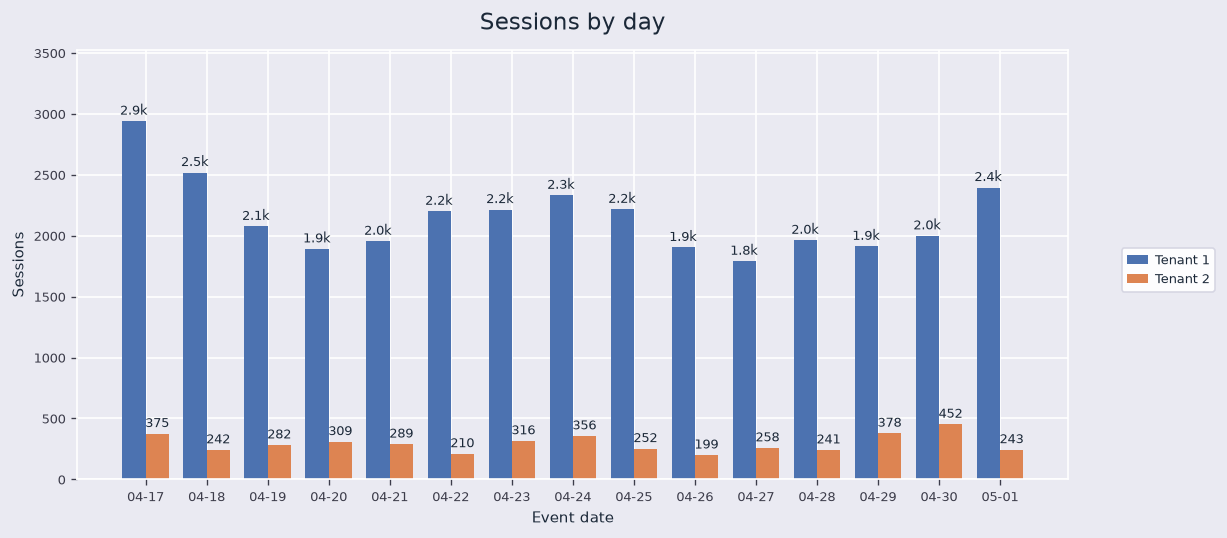

In [14]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
dates = list(frame["day"].drop_duplicates().sort_values())
tenants = sorted(frame["tenant"].unique())
x = np.arange(len(dates))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 4.6))
peak = 0
series = []
for tenant in tenants:
    values = (
        frame.loc[frame["tenant"] == tenant]
        .set_index("day")
        .reindex(dates)["unique_sessions"]
        .fillna(0)
        .to_numpy(dtype=float)
    )
    series.append(values)
    peak = max(peak, float(values.max()))
for i, (tenant, values) in enumerate(zip(tenants, series)):
    bars = ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=tenant_name(tenant),
        color=f"C{i}",
    )
    other = series[1 - i] if len(series) == 2 else None
    for j, (bar, value) in enumerate(zip(bars, values)):
        close = other is not None and abs(value - other[j]) < peak * 0.06
        point(
            ax,
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            short_num(value),
            xytext=(0, 9 if close and i else 2),
        )
ax.set_xticks(x)
ax.set_xticklabels([day.strftime("%m-%d") for day in dates])
ax.set_ylim(0, peak * 1.2)
polish(ax, "Sessions by day", xlabel="Event date", ylabel="Sessions")
handles, labels = ax.get_legend_handles_labels()
place_legend(fig, handles, labels)
plt.show()


## Most visits reach a purchase

A visit counts at a step if that event shows up at least once. The top line is the step. The bottom line is the count and the share of all visits. Those labels are the real shares. The drawing uses an even taper unless `PROPORTIONAL` is on, so band width is not the share. Set `PROPORTIONAL = True` to size the bands from the counts. The taper stays shallow because most visits still pay.

About 7 in 10 visits already buy (71.5% and 73.7%). The menu is not broken. The work is the minority who look and leave, and the smaller group who cart and do not pay. Do not redesign the whole flow for the people who already finish.


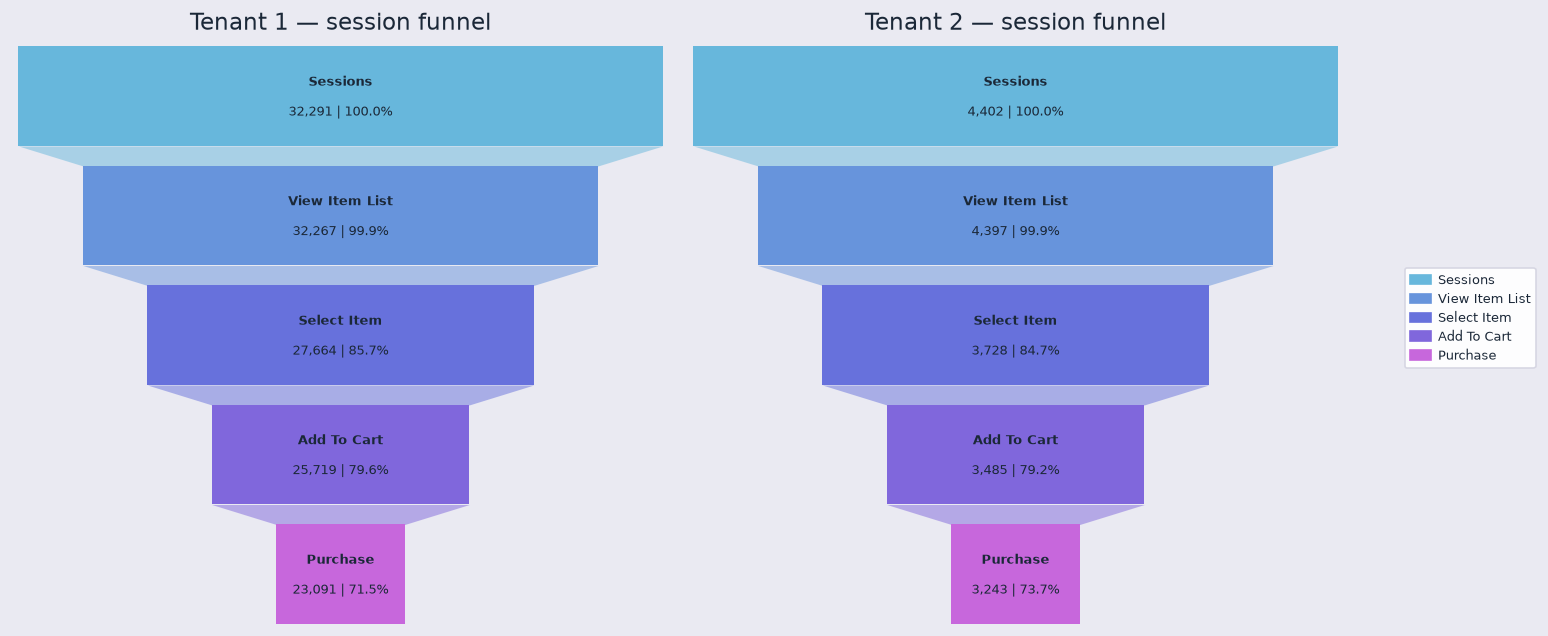

In [16]:
from matplotlib.patches import Patch

session_flags = load_session_flags()
funnel = (
    session_flags.groupby("tenant", as_index=False)
    .agg(
        sessions=("session_id", "size"),
        viewed=("viewed", "sum"),
        selected=("selected", "sum"),
        carted=("carted", "sum"),
        purchased=("purchased", "sum"),
    )
    .sort_values("tenant")
)

stages = ["sessions", "view_item_list", "select_item", "add_to_cart", "purchase"]
columns = ["sessions", "viewed", "selected", "carted", "purchased"]
colors = ["#67B7DC", "#6794DC", "#6771DC", "#8067DC", "#C767DC"]
# False keeps an even taper. True uses the session counts, and the taper stays shallow.
PROPORTIONAL = False


def draw_funnel(ax, labels, values):
    n = len(values)
    if PROPORTIONAL:
        half = [value / values[0] for value in values]
    else:
        half = [1 - i * (0.8 / (n - 1)) for i in range(n)]
    body, neck = 1.0, 0.2
    y = n * body + (n - 1) * neck
    for i, (label, value, color) in enumerate(zip(labels, values, colors)):
        share = 100 * value / values[0]
        y_top = y
        y_body = y_top - body
        ax.fill_betweenx([y_body, y_top], -half[i], half[i], color=color, linewidth=0)
        if i < n - 1:
            y_bot = y_body - neck
            ax.fill_betweenx(
                [y_bot, y_body],
                [-half[i + 1], -half[i]],
                [half[i + 1], half[i]],
                color=color,
                alpha=0.5,
                linewidth=0,
            )
            y = y_bot
        mid = (y_top + y_body) / 2
        name = label.replace("_", " ").title()
        ax.text(0, mid + 0.14, name, ha="center", va="center", fontsize=POINT, fontweight="bold", color="#1B2838", clip_on=True)
        ax.text(0, mid - 0.16, f"{value:,} | {share:.1f}%", ha="center", va="center", fontsize=POINT, color="#1B2838", clip_on=True)
    ax.set_xlim(-1.02, 1.02)
    ax.set_ylim(0, n * body + (n - 1) * neck)
    ax.set_axis_off()


tenants = list(funnel["tenant"])
fig, axes = plt.subplots(1, len(tenants), figsize=(7.5 * len(tenants), 5.4))
if len(tenants) == 1:
    axes = [axes]
for ax, tenant in zip(axes, tenants):
    row = funnel.loc[funnel["tenant"] == tenant].iloc[0]
    counts = [int(row[column]) for column in columns]
    draw_funnel(ax, stages, counts)
    ax.set_title(f"{tenant_name(tenant)} — session funnel", fontsize=TITLE, pad=10)
handles = [
    Patch(color=color, label=stage.replace("_", " ").title())
    for stage, color in zip(stages, colors)
]
place_legend(fig, handles, [handle.get_label() for handle in handles])
plt.show()


## Where the sessions are lost

The funnel shows who is still in. This chart shows who dropped at each handoff, as a percent of visits that reached the prior step.

Both brands lose the most between view and select (14.3% and 15.2%). People open the list and do not pick. That leak is almost the same at both tenants, so copying Tenant 2 will not fix it.

The leak that differs is cart to purchase. Tenant 1 loses 10.2%. Tenant 2 loses 6.9%. Those guests already chose an item. That is the checkout problem, and it is the one worth a test.


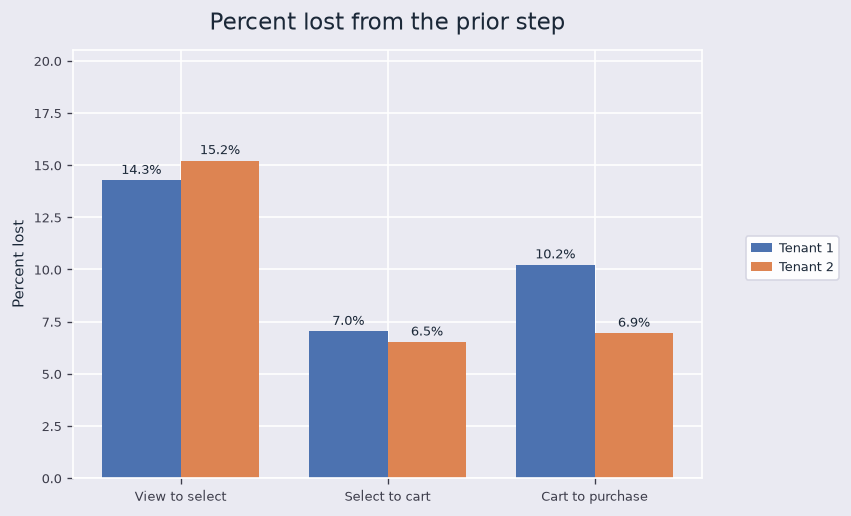

In [18]:
import numpy as np

session_flags = load_session_flags()
steps = [
    ("View to select", "selected", "viewed"),
    ("Select to cart", "carted", "selected"),
    ("Cart to purchase", "purchased", "carted"),
]
tenants = sorted(session_flags["tenant"].unique())
x = np.arange(len(steps))
width = 0.38
fig, ax = plt.subplots(figsize=(8, 4.4))
peak = 0
for i, tenant in enumerate(tenants):
    frame = session_flags.loc[session_flags["tenant"] == tenant]
    lost = [100 * (1 - frame[num].sum() / frame[den].sum()) for _, num, den in steps]
    peak = max(peak, max(lost))
    bars = ax.bar(x + (i - 0.5) * width, lost, width, label=tenant_name(tenant), color=f"C{i}")
    for bar, value in zip(bars, lost):
        point(ax, bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.1f}%")
ax.set_xticks(x)
ax.set_xticklabels([name for name, _, _ in steps])
ax.set_ylim(0, peak * 1.35)
polish(ax, "Percent lost from the prior step", ylabel="Percent lost")
handles, labels = ax.get_legend_handles_labels()
place_legend(fig, handles, labels)
plt.show()


## The basket is the same. The price unit is not.

Left: items in a visit that paid. Right: median price on a purchase row.

A paid visit is about two items either way (1.8 vs 1.6). Neither brand is winning by stuffing the basket. The right-hand scale is the warning. Median item price is about 10 for Tenant 1 and about 139 for Tenant 2. A bigger revenue sum is not a better business. Keep every dollar comparison inside one tenant.


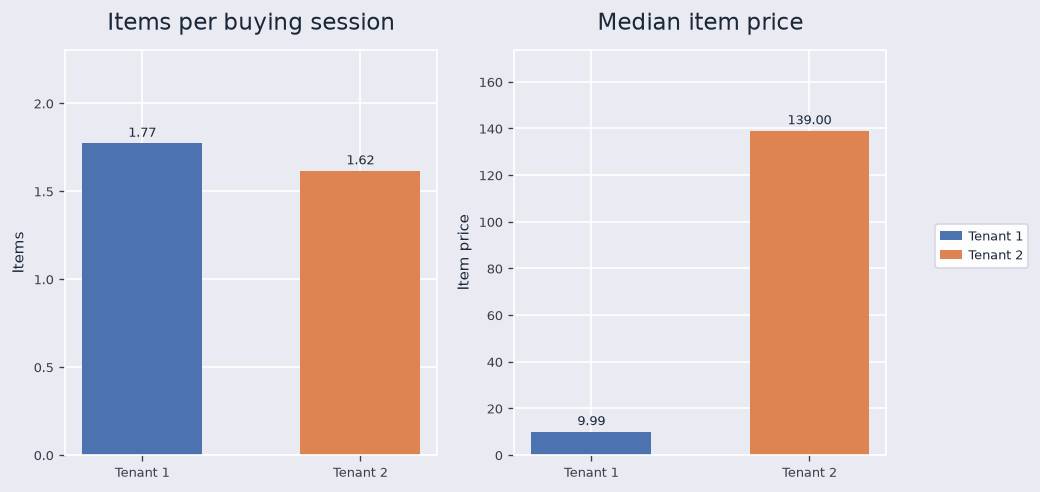

In [20]:
session_flags = load_session_flags()
prices = con.sql("""
SELECT tenant, MEDIAN(item_revenue) AS median_price
FROM events
WHERE event_name = 'purchase' AND item_revenue IS NOT NULL
GROUP BY tenant
ORDER BY tenant
""").df()

items = []
for tenant, frame in session_flags.groupby("tenant", sort=True):
    buyers = frame.loc[frame["purchased"].astype(bool)]
    items.append((tenant, buyers["purchase_rows"].sum() / len(buyers)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
names = [tenant_name(tenant) for tenant, _ in items]
vals = [value for _, value in items]
bars = axes[0].bar(names, vals, color=[f"C{i}" for i in range(len(items))], width=0.55)
for bar, name in zip(bars, names):
    bar.set_label(name)
for bar, val in zip(bars, vals):
    point(axes[0], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:.2f}")
axes[0].set_ylim(0, max(vals) * 1.3)
polish(axes[0], "Items per buying session", ylabel="Items")

price_names = [tenant_name(tenant) for tenant in prices["tenant"]]
price_vals = prices["median_price"].tolist()
bars = axes[1].bar(price_names, price_vals, color=[f"C{i}" for i in range(len(price_vals))], width=0.55)
for bar, val in zip(bars, price_vals):
    point(axes[1], bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{val:,.2f}")
axes[1].set_ylim(0, max(price_vals) * 1.25)
polish(axes[1], "Median item price", ylabel="Item price")
handles, labels = axes[0].get_legend_handles_labels()
place_legend(fig, handles, labels)
plt.show()


## Inside a tenant, busier days carry that tenant's revenue

Bars are visits. The line is item revenue for that tenant only. Each chart has its own revenue axis so the fifteen dates and both labels stay readable.

Inside one brand, a busy day is also a high-revenue day. More completed visits move that tenant's revenue with them. Do not put both brands on one dollar axis. Do not read Tenant 2's taller line as a win over Tenant 1.


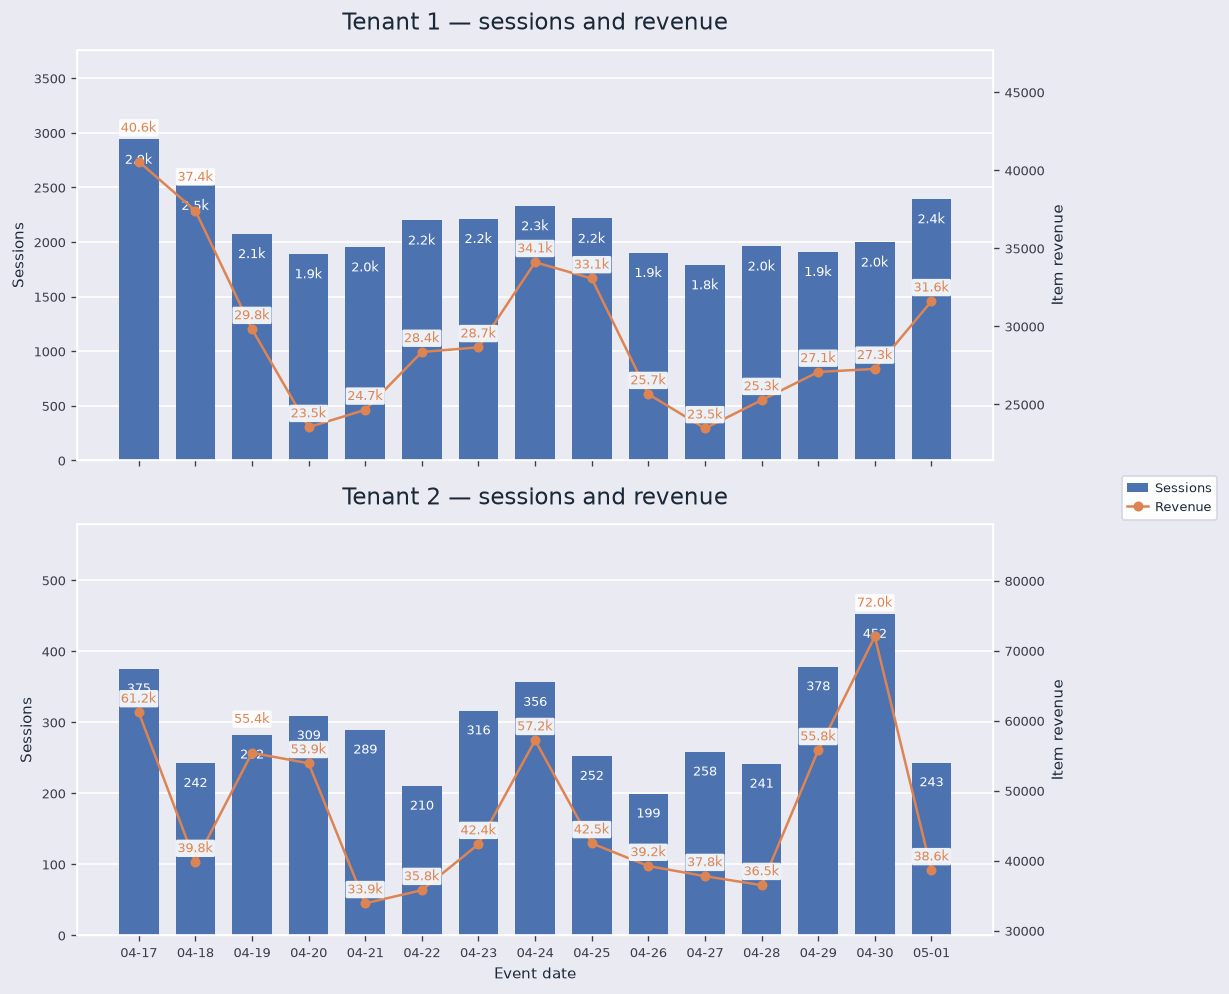

In [22]:
import numpy as np

daily = load_daily()
frame = daily.copy()
frame["day"] = frame["event_date"].dt.normalize()
tenants = list(frame.groupby("tenant", sort=True))
fig, axes = plt.subplots(len(tenants), 1, figsize=(12, 4.2 * len(tenants)), sharex=True)
if len(tenants) == 1:
    axes = [axes]

rev_axes = []
for ax, (tenant, part) in zip(axes, tenants):
    part = part.sort_values("day")
    x = np.arange(len(part))
    ax.bar(x, part["unique_sessions"], width=0.7, color="C0", label="Sessions")
    ax.set_ylim(0, part["unique_sessions"].max() * 1.28)
    rev = ax.twinx()
    rev_axes.append(rev)
    rev.set_facecolor("none")
    rev.patch.set_visible(False)
    rev.grid(False)
    rev.plot(x, part["total_item_revenue"], color="C1", marker="o", markersize=5, label="Revenue")
    low = part["total_item_revenue"].min()
    high = part["total_item_revenue"].max()
    span = high - low
    rev.set_ylim(low - span * 0.12, high + span * 0.42)
    fig.canvas.draw()
    for xpos, sessions, revenue in zip(x, part["unique_sessions"], part["total_item_revenue"]):
        session_px = ax.transData.transform((xpos, sessions))[1]
        revenue_px = rev.transData.transform((xpos, revenue))[1]
        point(
            ax,
            xpos,
            sessions,
            short_num(sessions),
            color="white",
            xytext=(0, -8),
            va="top",
        )
        point(
            rev,
            xpos,
            revenue,
            short_num(revenue),
            color="C1",
            xytext=(0, 16 if abs(session_px - revenue_px) < 22 else 4),
            va="bottom",
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9),
        )
    rev.set_ylabel("Item revenue", fontsize=9)
    rev.tick_params(labelsize=8, colors="#3C3C4A")
    rev.yaxis.label.set_color("#1B2838")
    for spine in rev.spines.values():
        spine.set_color("white")
    ax.set_xticks(x)
    ax.set_xticklabels([day.strftime("%m-%d") for day in part["day"]])
    polish(ax, f"{tenant_name(tenant)} — sessions and revenue", ylabel="Sessions", grid="y")

axes[-1].set_xlabel("Event date", fontsize=9)
bars, bar_labels = axes[0].get_legend_handles_labels()
lines, line_labels = rev_axes[0].get_legend_handles_labels()
place_legend(fig, bars + lines, bar_labels + line_labels)
plt.show()


## Stores differ more than the tenants do

Rate = visits with a purchase / all visits at the store. The label is that rate plus the kiosk count. Both charts share the percent axis. Tenant 2 has two stores, so that panel is the short one. The table is the same store list as before, sorted by conversion instead of raw revenue.

The brands look alike (71.5% and 73.7%). The stores do not. On Tenant 1, store 11478 converts at 58.8% with 2 kiosks. Store 15866 converts at 82.5% with 2 kiosks. Extra kiosks are not the higher rate. Tenant 2 store 278 has 4 kiosks and a lower rate than store 227. Coach the weak stores. Do not buy more machines to fix a menu or checkout problem.


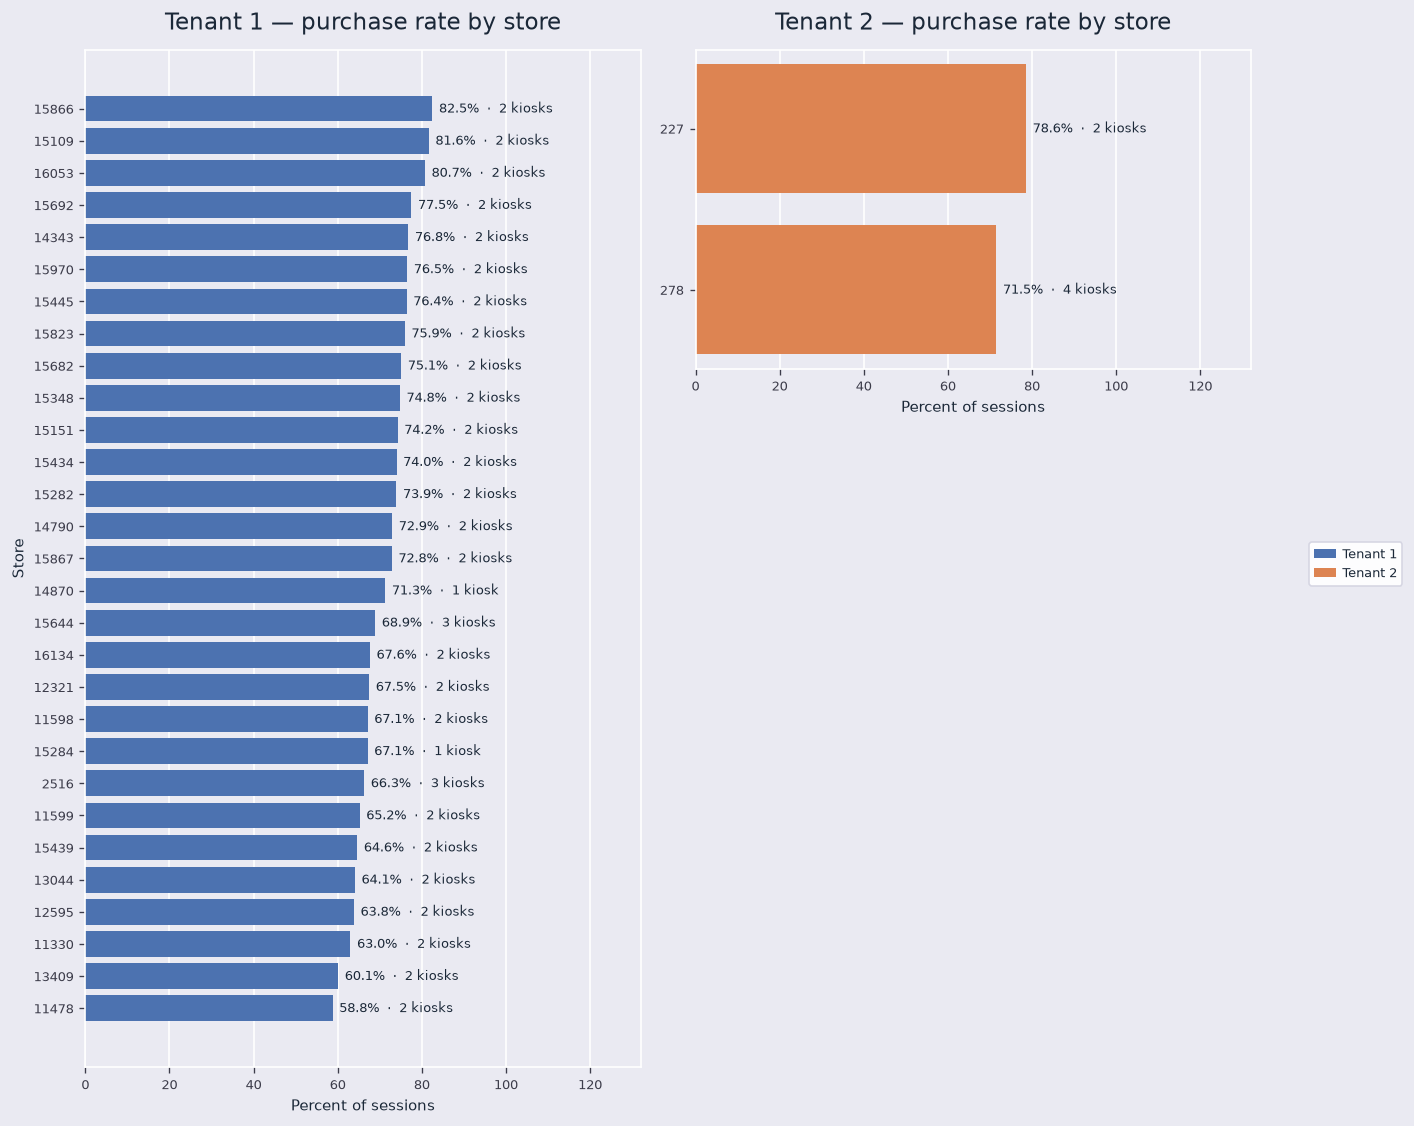

In [24]:
session_flags = load_session_flags()
store = (
    session_flags.groupby(["tenant", "store"], as_index=False)
    .agg(sessions=("session_id", "size"), purchased=("purchased", "sum"), kiosks=("kiosk", "nunique"))
)
store["rate"] = store["purchased"] / store["sessions"]
groups = [
    (tenant, frame.sort_values("rate", ascending=True))
    for tenant, frame in store.groupby("tenant", sort=True)
]
rows = max(len(frame) for _, frame in groups)
fig, axes = plt.subplots(1, len(groups), figsize=(14, 9.5), sharex=True)
if len(groups) == 1:
    axes = [axes]
for ax, (tenant, frame), color in zip(axes, groups, ["C0", "C1"]):
    y = list(range(len(frame)))
    ax.barh(y, frame["rate"] * 100, color=color, label=tenant_name(tenant))
    ax.set_yticks(y)
    ax.set_yticklabels(frame["store"].astype(str))
    for i, (rate, kiosks) in enumerate(zip(frame["rate"], frame["kiosks"])):
        kiosks = int(kiosks)
        noun = "kiosk" if kiosks == 1 else "kiosks"
        point(
            ax,
            rate * 100,
            i,
            f"{rate * 100:.1f}%  ·  {kiosks} {noun}",
            xytext=(4, 0),
            va="center",
            ha="left",
        )
    ax.set_xlim(0, 132)
    polish(
        ax,
        f"{tenant_name(tenant)} — purchase rate by store",
        xlabel="Percent of sessions",
        ylabel="Store" if len(frame) > 5 else None,
        grid="x",
    )
fig.tight_layout(rect=(0, 0, 0.76, 1))
tall = max(axes, key=lambda ax: len(ax.get_yticks()))
box = tall.get_position()
slot = box.height / rows
for ax, (_, frame) in zip(axes, groups):
    if len(frame) >= rows:
        continue
    pos = ax.get_position()
    height = max(slot * len(frame), 0.28)
    ax.set_position([pos.x0, box.y1 - height, pos.width, height])
handles, labels = [], []
for ax in axes:
    found_handles, found_labels = ax.get_legend_handles_labels()
    handles.extend(found_handles)
    labels.extend(found_labels)
fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(0.78, 0.5),
    **LEGEND,
)
plt.show()


## Findings you can act on

Same visit grain as the charts. Conversion is also `conversion_by_tenant` in `data/sql/metric_layer.sql`. The denominator is all visits for that tenant, or all visits at that store or kiosk.

### 1. Conversion

Purchase conversion = visits with at least one purchase ÷ all visits.

| Tenant | Sessions | Purchased | Purchase conversion |
| --- | ---: | ---: | ---: |
| Tenant 1 | 32,291 | 23,091 | 71.5% |
| Tenant 2 | 4,402 | 3,243 | 73.7% |

The brands already convert at nearly the same rate. A tenant-wide "get more people to buy" goal will not show you where to work. Track this rate, then look at the step they drop and the store they stand in. Keep this denominator. Do not switch the base to visits that opened the menu.

### 2. Churn

Customer churn cannot be measured here. There is no guest id, and the log is about 15 days. You cannot see a person leave the brand.

The substitute is a visit that reached the cart and never paid, divided by visits that reached the cart.

| Tenant | Reached cart | Cart, no purchase | Cart abandon rate |
| --- | ---: | ---: | ---: |
| Tenant 1 | 25,719 | 2,640 | 10.3% |
| Tenant 2 | 3,485 | 255 | 7.3% |

That is a guest walking away from a cart, not a customer who stopped coming back. Tenant 1 loses more of those carts. That is the gap the experiment below is built on.

### 3. Segmentation

RFM and LTV need a person you can see again. This file has visits, not people. The split that someone can act on is what the visit did:

| Segment | What the visit did | Tenant 1 | Tenant 2 | What to do |
| --- | --- | ---: | ---: | --- |
| Browse | Never carted, never paid | 6,560 (20.3%) | 904 (20.5%) | Help the first choice. Shorter list, a default meal. |
| Cart, no buy | Carted, never paid | 2,640 (8.2%) | 255 (5.8%) | Fix checkout. They already picked an item. |
| Purchased | Paid at least once | 23,091 (71.5%) | 3,243 (73.7%) | Keep that path stable. |

Browse is the same share at both brands, so copying Tenant 2 will not shrink it. Tenant 1 still has the count: 6,560 visits that never committed. Work the menu there, not a coupon after the fact.

Cart-no-buy is the smaller group and the one where the brands differ. Those guests were closest to paying. Checkout, payment, and the order review belong to this segment.

Purchased is most visits. Do not slow them down to chase the other two.

Manage this by store, not by a named customer. Store 11478 on Tenant 1 converts at 58.8% (2 kiosks, 764 visits). A store at 82.5% has the same kiosk count. Start the coaching list at the weak stores.

### 4. Experiment

One test. Tenant 1, cart to purchase. That step loses 10.2% of carts. Tenant 2 loses 6.9%. View-to-select is a bigger drop, but both brands have it, so it is a poor A/B target.

| Field | Choice |
| --- | --- |
| Hypothesis | A clearer cart and checkout on Tenant 1 raises the share of carts that pay from about 90% toward Tenant 2's 93%, without cutting revenue per buying session. |
| Unit | Session (one visit) |
| Primary metric | Carts that pay ÷ carts. Purchased ÷ carted. |
| Guardrail | Revenue per buying session, Tenant 1 only. Stop if it drops. |
| Sample | About 7,800 Tenant 1 visits that reach the cart (about 3,900 per arm) for a 3 point lift at 80% power, two-sided 5%. Tenant 1 sees about 1,700 carts a day, so that is about 5 days. Run 1–2 weeks so weekday and store mix are in both arms. |
| Expected impact | Closing a 3 point gap on about 25,700 carts is on the order of 850 extra paid visits in a 15-day window like this one. Each one is worth a Tenant 1 basket, not a Tenant 2 price. That is the size of the prize if the lift holds. It is not a forecast. |
| Risks | A longer checkout can slow people who already pay. Do not change prices or suggested items in the same test, or the guardrail moves for a different reason. A guest can come back and land in both arms, and this file cannot show that. Check the result by store: store 11478 is already far below the tenant, and a tenant average can hide a store that got worse. Run the test on Tenant 1 only. |

Do not score the test on raw event rows. Row counts mix basket size with whether the visit paid.


In [26]:
from IPython.display import display

segments = present(con.sql("""
WITH flags AS (
    SELECT
        tenant,
        session_id,
        MAX(event_name = 'add_to_cart') AS carted,
        MAX(event_name = 'purchase') AS purchased
    FROM events
    GROUP BY tenant, session_id
)
SELECT
    tenant,
    COUNT(*) AS sessions,
    COUNT(*) FILTER (WHERE purchased) AS purchased,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchased) / COUNT(*), 1) AS purchase_conversion_pct,
    COUNT(*) FILTER (WHERE NOT carted AND NOT purchased) AS browse,
    ROUND(100.0 * COUNT(*) FILTER (WHERE NOT carted AND NOT purchased) / COUNT(*), 1) AS browse_pct,
    COUNT(*) FILTER (WHERE carted AND NOT purchased) AS cart_no_buy,
    ROUND(100.0 * COUNT(*) FILTER (WHERE carted AND NOT purchased) / COUNT(*), 1) AS cart_no_buy_pct,
    COUNT(*) FILTER (WHERE carted) AS reached_cart,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE carted AND NOT purchased)
        / NULLIF(COUNT(*) FILTER (WHERE carted), 0),
        1
    ) AS cart_abandon_pct
FROM flags
GROUP BY tenant
ORDER BY tenant
""").df())
display(segments)

cart_step = present(con.sql("""
WITH flags AS (
    SELECT
        tenant,
        MAX(event_name = 'add_to_cart') AS carted,
        MAX(event_name = 'purchase') AS purchased
    FROM events
    GROUP BY tenant, session_id
)
SELECT
    tenant,
    COUNT(*) FILTER (WHERE carted) AS carted,
    COUNT(*) FILTER (WHERE purchased) AS purchased,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE purchased)
        / NULLIF(COUNT(*) FILTER (WHERE carted), 0),
        1
    ) AS cart_to_purchase_pct
FROM flags
GROUP BY tenant
ORDER BY tenant
""").df())
display(cart_step)


,tenant,sessions,purchased,purchase_conversion_pct,browse,browse_pct,cart_no_buy,cart_no_buy_pct,reached_cart,cart_abandon_pct
0,Tenant 1,32291,23091,71.5,6560,20.3,2640,8.2,25719,10.3
1,Tenant 2,4402,3243,73.7,904,20.5,255,5.8,3485,7.3


,tenant,carted,purchased,cart_to_purchase_pct
0,Tenant 1,25719,23091,89.8
1,Tenant 2,3485,3243,93.1


## Recommendations

This month, and the next two quarters. No new metric ships without a written definition. The issue to work first is carts that do not pay. Tenant 1 loses 10.2% of carts. Tenant 2 loses 6.9%.

### Quick wins

- Run the Tenant 1 cart-to-pay test for 1–2 weeks. Primary metric is carts that pay. Guardrail is revenue per buying session. Stop if that drops.
- Coach store 11478 before adding kiosks. It pays on 58.8% of visits. Store 15866 pays on 82.5%. Both run 2 kiosks, so the gap is the store, not the machine count.
- Keep the tracked rate as visits that pay, by store.

### Longer term

- Add a stable guest id.
- Measure a 90-day repeat visit.
- Publish one funnel dashboard with these definitions.

Do not add menu work to the same sprint as the checkout test. View to select is a bigger drop, and both brands have it. A guest id is an investigation, not a commitment, until the file can tell one person from the next.
